# DS605 — Lab Assignment 7
## Image Representation, PCA, Eigenfaces and Face Recognition
**Dataset:** AT&T Database of Faces (ORL)

This notebook loads grayscale images, represents them as vectors, computes PCA/eigenfaces using **NumPy linear algebra**, reconstructs images, performs nearest-neighbour matching, and compares traditional classifiers.

**Setup:** Download/extract ORL so the folder contains subject folders such as `s1`, `s2`, …, each containing face images. Update `DATASET_DIR` below. Scikit-learn is used only for the final classifiers, not for PCA.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42
DATASET_DIR = Path(r"C:\path\to\att_faces")  # CHANGE THIS
IMAGE_EXTENSIONS = {".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

## 2. Load grayscale images and labels

In [4]:
def load_dataset(root):
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(f"Dataset folder not found: {root}. Update DATASET_DIR.")
    vectors, labels, paths, shapes = [], [], [], set()
    subjects = sorted([p for p in root.iterdir() if p.is_dir()])
    for folder in subjects:
        files = sorted(p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
        for path in files:
            with Image.open(path) as im:
                arr = np.asarray(im.convert("L"), dtype=np.float64)
            vectors.append(arr.ravel()); labels.append(folder.name); paths.append(path)
            shapes.add(arr.shape)
    if not vectors:
        raise ValueError("No images found. Check folder layout and image extensions.")
    if len(shapes) != 1:
        raise ValueError(f"Images must have identical dimensions; found {shapes}")
    return np.vstack(vectors), np.asarray(labels), paths, next(iter(shapes))

X, y, image_paths, image_shape = load_dataset(r"C:\Users\Raaj Soni\OneDrive\Desktop\202618039_ML_assignment\lab_assignment_07\archive (4)")
print("Image matrix:", X.shape, "(images, pixels)")
print("Subjects:", len(np.unique(y)), "Image shape:", image_shape)
print("Pixel intensity range:", X.min(), "to", X.max())

Image matrix: (400, 10304) (images, pixels)
Subjects: 40 Image shape: (112, 92)
Pixel intensity range: 0.0 to 251.0


## 3. Inspect example images

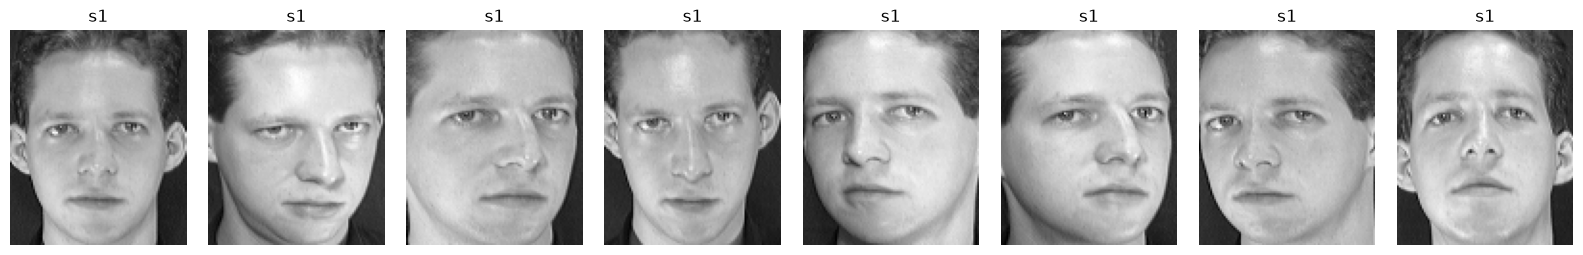

In [5]:
def show_samples(paths, labels, n=8):
    n = min(n, len(paths))
    fig, axes = plt.subplots(1, n, figsize=(2*n, 2.5))
    if n == 1: axes = [axes]
    for ax, path, label in zip(axes, paths[:n], labels[:n]):
        with Image.open(path) as im: ax.imshow(im.convert("L"), cmap="gray")
        ax.set_title(str(label)); ax.axis("off")
    plt.tight_layout(); plt.show()
show_samples(image_paths, y)

## 4. Stratified train-test split
Stratification aims to keep each subject represented in both sets. PCA is fitted on training data only to avoid test-data leakage.

In [6]:
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, image_paths, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("All subjects in both sets:", set(y_train) == set(y_test))

Train: (300, 10304) Test: (100, 10304)
All subjects in both sets: True


## 5. Mean face and PCA with NumPy SVD
For the centered training matrix, SVD yields principal directions in `Vt`. This satisfies the assignment requirement to implement PCA with NumPy linear algebra rather than `sklearn.decomposition.PCA`.

In [7]:
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face
U, singular_values, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
explained_variance = singular_values**2 / (len(X_train_centered) - 1)
explained_variance_ratio = explained_variance / explained_variance.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)
n_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
print("Available components:", len(singular_values))
print("Components needed for >=90% variance:", n_90)
print("Cumulative variance:", cumulative_variance[n_90-1])

Available components: 300
Components needed for >=90% variance: 94
Cumulative variance: 0.900094086217157


## 6. Explained variance plot

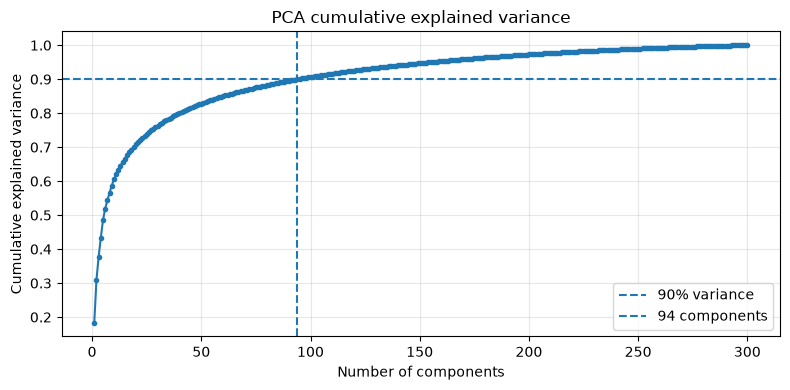

,component,explained_variance_ratio,cumulative_variance
0,1,0.183737,0.183737
1,2,0.125434,0.309172
2,3,0.068307,0.377479
3,4,0.056218,0.433697
4,5,0.051608,0.485305
5,6,0.034183,0.519488
6,7,0.023819,0.543307
7,8,0.022860,0.566167
8,9,0.020617,0.586784
9,10,0.018131,0.604915


In [8]:
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative_variance)+1), cumulative_variance, marker=".")
plt.axhline(.90, linestyle="--", label="90% variance")
plt.axvline(n_90, linestyle="--", label=f"{n_90} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"component": np.arange(1, len(explained_variance_ratio)+1),
              "explained_variance_ratio": explained_variance_ratio,
              "cumulative_variance": cumulative_variance}).head(10)

## 7. Visualize eigenfaces

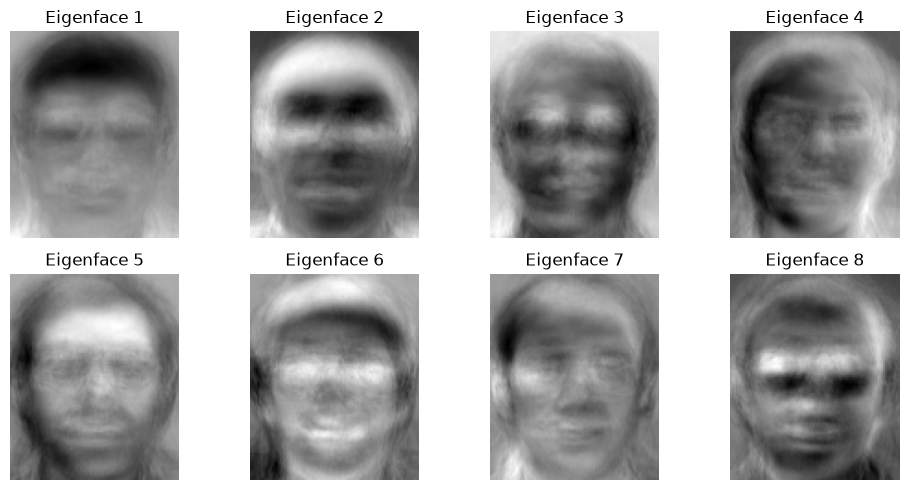

In [9]:
def show_eigenfaces(Vt, image_shape, n=8):
    n = min(n, len(Vt)); cols = 4; rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.5*rows)); axes = np.asarray(axes).reshape(-1)
    for i in range(n):
        axes[i].imshow(Vt[i].reshape(image_shape), cmap="gray")
        axes[i].set_title(f"Eigenface {i+1}"); axes[i].axis("off")
    for ax in axes[n:]: ax.axis("off")
    plt.tight_layout(); plt.show()
show_eigenfaces(Vt, image_shape, 8)

## 8. Project images into PCA space

In [10]:
N_COMPONENTS = min(n_90, Vt.shape[0])
components = Vt[:N_COMPONENTS].T
Z_train = X_train_centered @ components
Z_test = X_test_centered @ components
print("Components:", N_COMPONENTS, "Reduced train:", Z_train.shape, "Reduced test:", Z_test.shape)

Components: 94 Reduced train: (300, 94) Reduced test: (100, 94)


## 9. Reconstruct sample faces

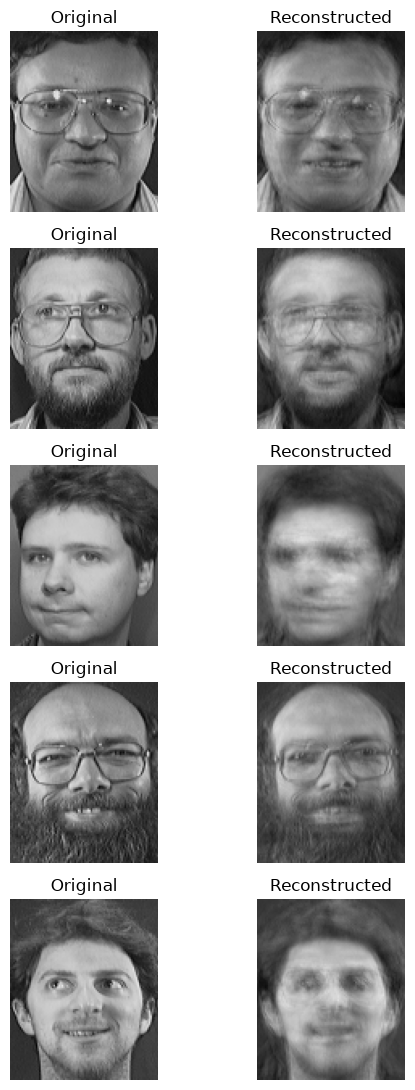

In [11]:
def plot_reconstructions(X_data, mean_face, components, image_shape, n=5):
    n = min(n, len(X_data)); fig, axes = plt.subplots(n, 2, figsize=(6, 2.2*n))
    if n == 1: axes = np.asarray([axes])
    for i in range(n):
        original = X_data[i]
        coeff = (original - mean_face) @ components
        recon = mean_face + coeff @ components.T
        axes[i, 0].imshow(original.reshape(image_shape), cmap="gray", vmin=0, vmax=255)
        axes[i, 0].set_title("Original")
        axes[i, 1].imshow(np.clip(recon, 0, 255).reshape(image_shape), cmap="gray", vmin=0, vmax=255)
        axes[i, 1].set_title("Reconstructed")
        axes[i, 0].axis("off"); axes[i, 1].axis("off")
    plt.tight_layout(); plt.show()
plot_reconstructions(X_test, mean_face, components, image_shape)

## 10. Reconstruction error and storage comparison

In [12]:
Z_recon = X_test_centered @ components
X_reconstructed = mean_face + Z_recon @ components.T
mse = np.mean((X_test - X_reconstructed)**2)
rmse = np.sqrt(mse)
print(f"Test reconstruction MSE: {mse:.3f}")
print(f"Test reconstruction RMSE: {rmse:.3f}")
print("Raw values per image:", X.shape[1])
print("PCA coefficients per image:", N_COMPONENTS)
print(f"Representation reduction: {100*(1-N_COMPONENTS/X.shape[1]):.2f}%")

Test reconstruction MSE: 343.401
Test reconstruction RMSE: 18.531
Raw values per image: 10304
PCA coefficients per image: 94
Representation reduction: 99.09%


## 11. Nearest-neighbour face matching
For each test face, choose the closest training projection using Euclidean distance.

In [13]:
def nearest_neighbor_predict(Z_train, y_train, Z_query, chunk_size=128):
    preds = []
    train_sq = np.sum(Z_train**2, axis=1)[None, :]
    for start in range(0, len(Z_query), chunk_size):
        q = Z_query[start:start+chunk_size]
        dist_sq = np.sum(q**2, axis=1, keepdims=True) + train_sq - 2*q @ Z_train.T
        idx = np.argmin(np.maximum(dist_sq, 0), axis=1)
        preds.extend(y_train[idx])
    return np.asarray(preds)

y_pred_nn = nearest_neighbor_predict(Z_train, y_train, Z_test)
nn_accuracy = accuracy_score(y_test, y_pred_nn)
print(f"PCA nearest-neighbour accuracy: {nn_accuracy:.3f}")
print(classification_report(y_test, y_pred_nn, zero_division=0))

PCA nearest-neighbour accuracy: 0.960
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         2
         s10       1.00      0.67      0.80         3
         s11       1.00      1.00      1.00         3
         s12       1.00      1.00      1.00         3
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         3
         s15       0.67      1.00      0.80         2
         s16       1.00      1.00      1.00         3
         s17       1.00      1.00      1.00         2
         s18       1.00      1.00      1.00         2
         s19       1.00      0.67      0.80         3
          s2       0.75      1.00      0.86         3
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         3
         s23       1.00      1.00      1.00         2
         s24       1.00      1.00      1.00

## 12. Inspect correct and incorrect matches

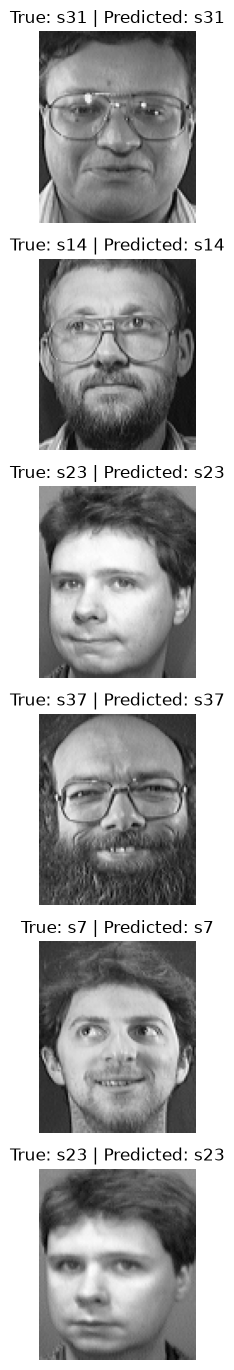

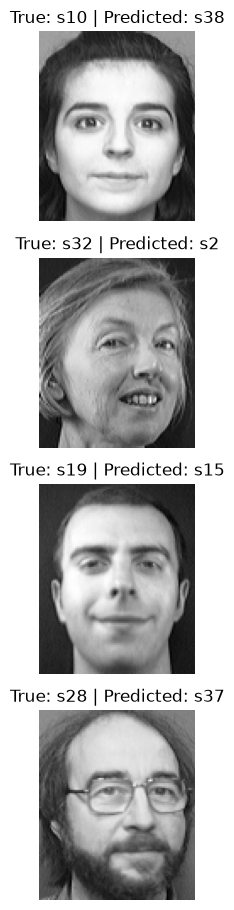

In [14]:
def show_match_examples(paths, y_true, y_pred, correct=True, n=6):
    indices = np.flatnonzero((y_true == y_pred) if correct else (y_true != y_pred))[:n]
    if len(indices) == 0:
        print("No examples in this category."); return
    fig, axes = plt.subplots(len(indices), 1, figsize=(3, 2.3*len(indices)))
    if len(indices) == 1: axes = [axes]
    for ax, i in zip(axes, indices):
        with Image.open(paths[i]) as im: ax.imshow(im.convert("L"), cmap="gray")
        ax.set_title(f"True: {y_true[i]} | Predicted: {y_pred[i]}"); ax.axis("off")
    plt.tight_layout(); plt.show()
show_match_examples(paths_test, y_test, y_pred_nn, correct=True)
show_match_examples(paths_test, y_test, y_pred_nn, correct=False)

## 13. Compare raw pixels vs PCA nearest neighbour

In [15]:
y_pred_raw = nearest_neighbor_predict(X_train, y_train, X_test)
raw_accuracy = accuracy_score(y_test, y_pred_raw)
comparison = pd.DataFrame([
    {"method": "Nearest neighbour on raw pixels", "accuracy": raw_accuracy},
    {"method": f"Nearest neighbour on PCA ({N_COMPONENTS} components)", "accuracy": nn_accuracy}
])
comparison

,method,accuracy
0,Nearest neighbour on raw pixels,0.96
1,Nearest neighbour on PCA (94 components),0.96


## 14. Compare traditional classifiers on PCA features
PCA features are generated above by NumPy. Scikit-learn is used here only for classifiers.

In [16]:
classifiers = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale")
}
classifier_results = []
trained_models = {}
for name, clf in classifiers.items():
    model = make_pipeline(StandardScaler(), clf)
    model.fit(Z_train, y_train)
    pred = model.predict(Z_test)
    classifier_results.append({"method": name, "accuracy": accuracy_score(y_test, pred)})
    trained_models[name] = model
all_results = pd.concat([comparison, pd.DataFrame(classifier_results)], ignore_index=True)
all_results.sort_values("accuracy", ascending=False).reset_index(drop=True)

,method,accuracy
0,Nearest neighbour on raw pixels,0.96
1,Nearest neighbour on PCA (94 components),0.96
2,Logistic Regression,0.96
3,SVM (RBF),0.93
4,KNN (k=3),0.82


### Accuracy plot

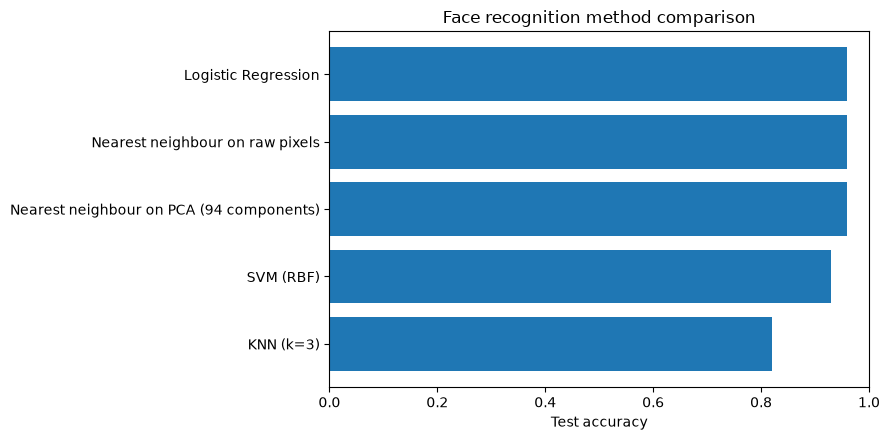

In [17]:
plot_df = all_results.sort_values("accuracy")
plt.figure(figsize=(9, 4.5))
plt.barh(plot_df["method"], plot_df["accuracy"])
plt.xlim(0, 1); plt.xlabel("Test accuracy"); plt.title("Face recognition method comparison")
plt.tight_layout(); plt.show()

## 15. Experiment with different component counts

In [18]:
candidate_counts = sorted(set([min(k, Vt.shape[0]) for k in (10, 20, 40, n_90)]))
rows = []
for k in candidate_counts:
    basis = Vt[:k].T
    train_k = X_train_centered @ basis
    test_k = X_test_centered @ basis
    pred_k = nearest_neighbor_predict(train_k, y_train, test_k)
    rows.append({"components": k,
                 "cumulative_explained_variance": cumulative_variance[k-1],
                 "nearest_neighbour_accuracy": accuracy_score(y_test, pred_k)})
component_experiment = pd.DataFrame(rows).drop_duplicates("components")
component_experiment

,components,cumulative_explained_variance,nearest_neighbour_accuracy
0,10,0.604915,0.95
1,20,0.707995,0.95
2,40,0.800545,0.96
3,94,0.900094,0.96


## 16. Confusion matrix for best PCA classifier

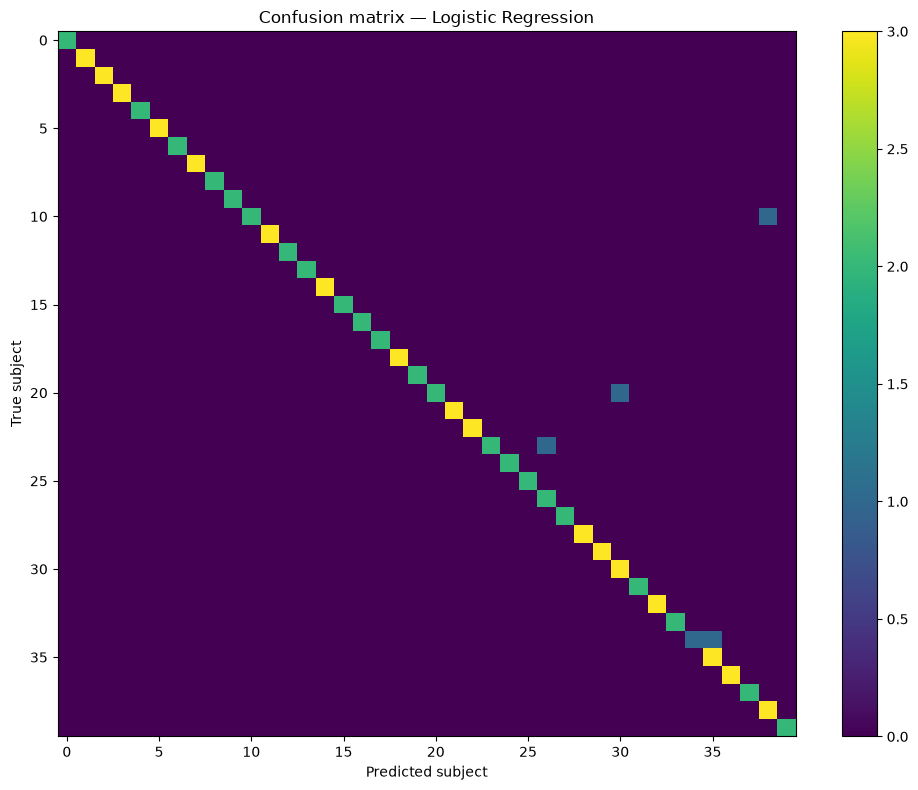

Best PCA classifier: Logistic Regression
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         2
         s10       1.00      1.00      1.00         3
         s11       1.00      1.00      1.00         3
         s12       1.00      1.00      1.00         3
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         3
         s15       1.00      1.00      1.00         2
         s16       1.00      1.00      1.00         3
         s17       1.00      1.00      1.00         2
         s18       1.00      1.00      1.00         2
         s19       1.00      0.67      0.80         3
          s2       1.00      1.00      1.00         3
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         3
         s23       1.00      1.00      1.00         2
         s24       1.00      1.00      1

In [19]:
best_name = max(classifier_results, key=lambda r: r["accuracy"])["method"]
best_model = trained_models[best_name]
best_pred = best_model.predict(Z_test)
subject_labels = sorted(np.unique(y))
cm = confusion_matrix(y_test, best_pred, labels=subject_labels)
plt.figure(figsize=(10, 8)); plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title(f"Confusion matrix — {best_name}"); plt.xlabel("Predicted subject"); plt.ylabel("True subject")
plt.colorbar(); plt.tight_layout(); plt.show()
print("Best PCA classifier:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

## 17. Results summary

In [20]:
summary = {
    "images": int(X.shape[0]), "subjects": int(len(np.unique(y))),
    "pixels_per_image": int(X.shape[1]), "train_images": int(len(X_train)),
    "test_images": int(len(X_test)), "components_for_90_percent_variance": int(n_90),
    "variance_at_selected_count": float(cumulative_variance[N_COMPONENTS-1]),
    "reconstruction_rmse": float(rmse), "raw_pixel_nn_accuracy": float(raw_accuracy),
    "pca_nn_accuracy": float(nn_accuracy), "best_pca_classifier": best_name,
    "best_pca_classifier_accuracy": float(max(r["accuracy"] for r in classifier_results))
}
pd.Series(summary, name="value").to_frame()

,value
images,400
subjects,40
pixels_per_image,10304
train_images,300
test_images,100
components_for_90_percent_variance,94
variance_at_selected_count,0.900094
reconstruction_rmse,18.531083
raw_pixel_nn_accuracy,0.96
pca_nn_accuracy,0.96
